In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

# Load the California Housing dataset
housing = fetch_california_housing()

X = housing.data
y = housing.target

print("California Housing Dataset")
print("----------------------------")
print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)
print("Feature names:", housing.feature_names)


California Housing Dataset
----------------------------
Feature matrix shape: (20640, 8)
Target vector shape: (20640,)
Feature names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [2]:

# Split the real-world dataset
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=500, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    train_size=100,
    test_size=30,
    random_state=42
)

print("Real-World Dataset Split")
print("----------------------------")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Real-World Dataset Split
----------------------------
Training: (100, 8)
Validation: (30, 8)
Test: (500, 8)


In [3]:

from sklearn.preprocessing import StandardScaler

# Fit the scaler using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Feature Standardization Completed!")
print("--------------------------------")
print("Training shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)
print("Test shape:", X_test_scaled.shape)
print("Training feature means:", np.round(X_train_scaled.mean(axis=0), 2))


Feature Standardization Completed!
--------------------------------
Training shape: (100, 8)
Validation shape: (30, 8)
Test shape: (500, 8)
Training feature means: [-0.  0.  0. -0.  0. -0.  0.  0.]


In [4]:

# Generate Random Fourier Features
rng = np.random.default_rng(42)

max_features = 300
gamma = 0.1

# Fixed random transformation
W = rng.normal(
    scale=np.sqrt(2 * gamma),
    size=(X_train_scaled.shape[1], max_features)
)
b = rng.uniform(0, 2 * np.pi, size=max_features)

# Apply the same transformation to each dataset
X_train_rff = np.cos(X_train_scaled @ W + b)
X_val_rff = np.cos(X_val_scaled @ W + b)
X_test_rff = np.cos(X_test_scaled @ W + b)

print("Random Fourier Features Generated!")
print("--------------------------------")
print("Training:", X_train_rff.shape)
print("Validation:", X_val_rff.shape)
print("Test:", X_test_rff.shape)


Random Fourier Features Generated!
--------------------------------
Training: (100, 300)
Validation: (30, 300)
Test: (500, 300)


In [5]:

import sys
from pathlib import Path

# Import our Least Squares implementation
sys.path.insert(0, str(Path.cwd().parent / "src"))
from linear_models import least_squares

# Feature dimensions
real_dimensions = [
    10, 20, 40, 60, 80, 90, 95, 98, 99,
    100, 101, 102, 105, 110, 120, 150, 200, 250, 300
]

real_train_errors = []
real_test_errors = []

for d in real_dimensions:
    X_tr = X_train_rff[:, :d]
    X_te = X_test_rff[:, :d]

    # Train Least Squares
    w = least_squares(X_tr, y_train)

    # Calculate training and test errors
    train_mse = np.mean((y_train - X_tr @ w) ** 2)
    test_mse = np.mean((y_test - X_te @ w) ** 2)

    real_train_errors.append(train_mse)
    real_test_errors.append(test_mse)

    print(f"d={d:3d} | Train MSE={train_mse:.4f} | Test MSE={test_mse:.4f}")


d= 10 | Train MSE=2.3845 | Test MSE=2.1863
d= 20 | Train MSE=1.1970 | Test MSE=1.7491
d= 40 | Train MSE=0.5460 | Test MSE=1.1975
d= 60 | Train MSE=0.3355 | Test MSE=1.9044
d= 80 | Train MSE=0.0892 | Test MSE=15.4929
d= 90 | Train MSE=0.0370 | Test MSE=26.9026
d= 95 | Train MSE=0.0282 | Test MSE=74.4046
d= 98 | Train MSE=0.0042 | Test MSE=62.1686
d= 99 | Train MSE=0.0005 | Test MSE=44.1199
d=100 | Train MSE=0.0000 | Test MSE=45.5625
d=101 | Train MSE=0.0000 | Test MSE=41.7154
d=102 | Train MSE=0.0000 | Test MSE=35.4333
d=105 | Train MSE=0.0000 | Test MSE=29.5284
d=110 | Train MSE=0.0000 | Test MSE=20.4240
d=120 | Train MSE=0.0000 | Test MSE=12.4687
d=150 | Train MSE=0.0000 | Test MSE=8.2294
d=200 | Train MSE=0.0000 | Test MSE=5.7800
d=250 | Train MSE=0.0000 | Test MSE=3.8493
d=300 | Train MSE=0.0000 | Test MSE=3.2422


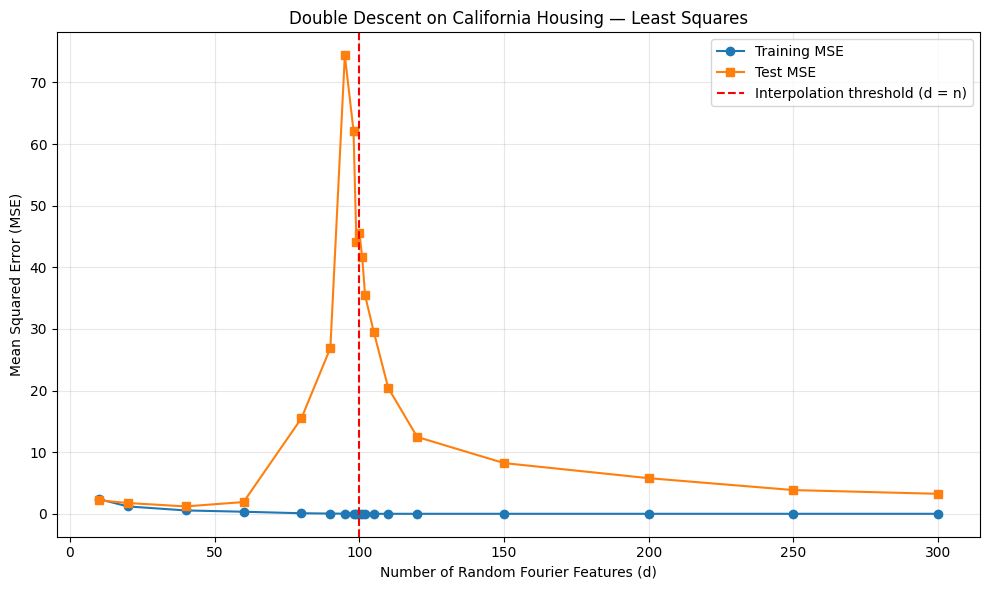

In [20]:

# Visualize Double Descent on California Housing
plt.figure(figsize=(10, 6))

plt.plot(
    real_dimensions,
    real_train_errors,
    marker="o",
    label="Training MSE"
)

plt.plot(
    real_dimensions,
    real_test_errors,
    marker="s",
    label="Test MSE"
)

# Mark the interpolation threshold
plt.axvline(
    x=100,
    color="red",
    linestyle="--",
    label="Interpolation threshold (d = n)"
)

plt.xlabel("Number of Random Fourier Features (d)")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Double Descent on California Housing — Least Squares")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("../results/GRAPH_NAME.png", dpi=300, bbox_inches="tight")
plt.show()


In [21]:

# Import our Ridge Regression implementation
from linear_models import ridge_regression

# Preliminary Ridge experiment
alpha = 1.0

real_ridge_train_errors = []
real_ridge_test_errors = []

for d in real_dimensions:
    X_tr = X_train_rff[:, :d]
    X_te = X_test_rff[:, :d]

    # Train Ridge Regression
    w = ridge_regression(X_tr, y_train, alpha=alpha)

    # Calculate errors
    train_mse = np.mean((y_train - X_tr @ w) ** 2)
    test_mse = np.mean((y_test - X_te @ w) ** 2)

    real_ridge_train_errors.append(train_mse)
    real_ridge_test_errors.append(test_mse)

    print(f"d={d:3d} | Train MSE={train_mse:.4f} | Test MSE={test_mse:.4f}")


d= 10 | Train MSE=2.3856 | Test MSE=2.1930
d= 20 | Train MSE=1.2082 | Test MSE=1.6560
d= 40 | Train MSE=0.5668 | Test MSE=1.0331
d= 60 | Train MSE=0.4177 | Test MSE=0.8357
d= 80 | Train MSE=0.2567 | Test MSE=0.6606
d= 90 | Train MSE=0.2464 | Test MSE=0.6718
d= 95 | Train MSE=0.2315 | Test MSE=0.6904
d= 98 | Train MSE=0.2231 | Test MSE=0.6650
d= 99 | Train MSE=0.2219 | Test MSE=0.6666
d=100 | Train MSE=0.2216 | Test MSE=0.6716
d=101 | Train MSE=0.2221 | Test MSE=0.6549
d=102 | Train MSE=0.2197 | Test MSE=0.6742
d=105 | Train MSE=0.2182 | Test MSE=0.6510
d=110 | Train MSE=0.2123 | Test MSE=0.6762
d=120 | Train MSE=0.1776 | Test MSE=0.8114
d=150 | Train MSE=0.1326 | Test MSE=1.0255
d=200 | Train MSE=0.0995 | Test MSE=0.9780
d=250 | Train MSE=0.0753 | Test MSE=0.9985
d=300 | Train MSE=0.0540 | Test MSE=1.0493


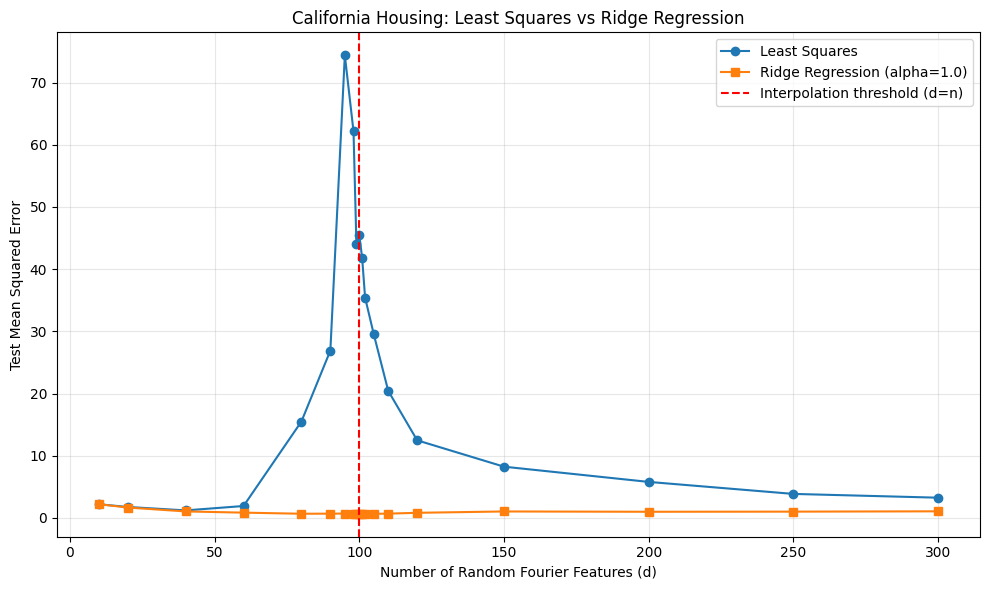

In [22]:

# Compare Least Squares and Ridge on California Housing
plt.figure(figsize=(10, 6))

plt.plot(
    real_dimensions,
    real_test_errors,
    marker="o",
    label="Least Squares"
)

plt.plot(
    real_dimensions,
    real_ridge_test_errors,
    marker="s",
    label="Ridge Regression (alpha=1.0)"
)

plt.axvline(
    x=100,
    color="red",
    linestyle="--",
    label="Interpolation threshold (d=n)"
)

plt.xlabel("Number of Random Fourier Features (d)")
plt.ylabel("Test Mean Squared Error")
plt.title("California Housing: Least Squares vs Ridge Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("../results/california_regularization_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [23]:

# Ridge hyperparameter selection using validation data
alpha_values = [0.01, 0.1, 1.0, 10.0, 100.0]
validation_mse = []

d = 100

for alpha in alpha_values:
    # Train using training observations only
    w = ridge_regression(X_train_rff[:, :d], y_train, alpha=alpha)

    # Evaluate using validation observations
    predictions = X_val_rff[:, :d] @ w
    mse = np.mean((y_val - predictions) ** 2)

    validation_mse.append(mse)

    print(f"alpha={alpha:6.2f} | Validation MSE={mse:.4f}")

best_index = np.argmin(validation_mse)
best_alpha_real = alpha_values[best_index]

print("--------------------------------")
print(f"Selected alpha: {best_alpha_real}")
print(f"Lowest validation MSE: {validation_mse[best_index]:.4f}")


alpha=  0.01 | Validation MSE=6.5546
alpha=  0.10 | Validation MSE=3.0960
alpha=  1.00 | Validation MSE=1.5224
alpha= 10.00 | Validation MSE=1.0059
alpha=100.00 | Validation MSE=1.0434
--------------------------------
Selected alpha: 10.0
Lowest validation MSE: 1.0059


In [24]:

# Evaluate validation-selected Ridge at d = 100
d = 100

# Train using the original training set
w = ridge_regression(
    X_train_rff[:, :d],
    y_train,
    alpha=best_alpha_real
)

# Evaluate on the untouched test set
predictions = X_test_rff[:, :d] @ w
ridge_test_mse = np.mean((y_test - predictions) ** 2)

print("California Housing — Final Ridge Evaluation")
print("-------------------------------------------")
print(f"Selected alpha: {best_alpha_real}")
print(f"Feature dimension: {d}")
print(f"Test MSE: {ridge_test_mse:.4f}")


California Housing — Final Ridge Evaluation
-------------------------------------------
Selected alpha: 10.0
Feature dimension: 100
Test MSE: 0.6908


In [25]:

# Tune Ridge regularization across feature dimensions
alpha_grid = [0.01, 0.1, 1.0, 10.0, 100.0]

selected_alphas = []
tuned_ridge_test_errors = []

for d in real_dimensions:
    val_errors = []

    for alpha in alpha_grid:
        w = ridge_regression(
            X_train_rff[:, :d], y_train, alpha=alpha
        )

        val_pred = X_val_rff[:, :d] @ w
        val_mse = np.mean((y_val - val_pred) ** 2)
        val_errors.append(val_mse)

    # Select alpha using validation error only
    best_alpha_d = alpha_grid[np.argmin(val_errors)]
    selected_alphas.append(best_alpha_d)

    # Evaluate selected model on test data
    w = ridge_regression(
        X_train_rff[:, :d], y_train, alpha=best_alpha_d
    )

    test_pred = X_test_rff[:, :d] @ w
    test_mse = np.mean((y_test - test_pred) ** 2)
    tuned_ridge_test_errors.append(test_mse)

    print(f"d={d:3d} | Best alpha={best_alpha_d:6.2f} | Test MSE={test_mse:.4f}")


d= 10 | Best alpha=  0.01 | Test MSE=2.1864
d= 20 | Best alpha= 10.00 | Test MSE=1.5448
d= 40 | Best alpha=100.00 | Test MSE=1.5442
d= 60 | Best alpha=100.00 | Test MSE=1.3763
d= 80 | Best alpha= 10.00 | Test MSE=0.6919
d= 90 | Best alpha= 10.00 | Test MSE=0.6998
d= 95 | Best alpha= 10.00 | Test MSE=0.6957
d= 98 | Best alpha= 10.00 | Test MSE=0.6917
d= 99 | Best alpha= 10.00 | Test MSE=0.6923
d=100 | Best alpha= 10.00 | Test MSE=0.6908
d=101 | Best alpha= 10.00 | Test MSE=0.6670
d=102 | Best alpha= 10.00 | Test MSE=0.6675
d=105 | Best alpha= 10.00 | Test MSE=0.6457
d=110 | Best alpha= 10.00 | Test MSE=0.6601
d=120 | Best alpha= 10.00 | Test MSE=0.6489
d=150 | Best alpha= 10.00 | Test MSE=0.6789
d=200 | Best alpha=100.00 | Test MSE=0.9311
d=250 | Best alpha=100.00 | Test MSE=0.8380
d=300 | Best alpha=100.00 | Test MSE=0.8220


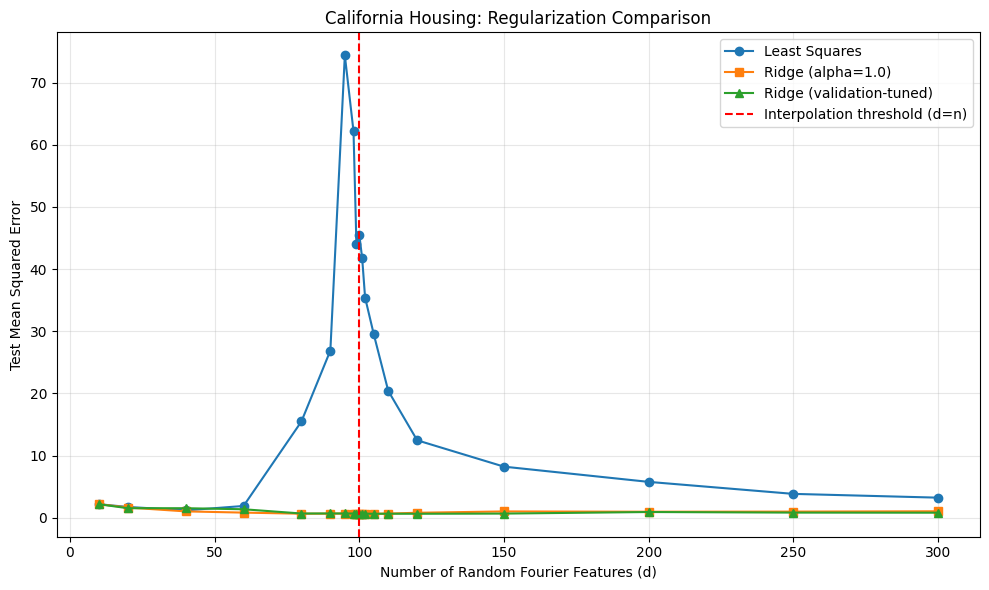

In [28]:

# Compare Least Squares, fixed Ridge, and tuned Ridge
plt.figure(figsize=(10, 6))

plt.plot(
    real_dimensions, real_test_errors,
    marker="o", label="Least Squares"
)

plt.plot(
    real_dimensions, real_ridge_test_errors,
    marker="s", label="Ridge (alpha=1.0)"
)

plt.plot(
    real_dimensions, tuned_ridge_test_errors,
    marker="^", label="Ridge (validation-tuned)"
)

plt.axvline(
    x=100, color="red", linestyle="--",
    label="Interpolation threshold (d=n)"
)

plt.xlabel("Number of Random Fourier Features (d)")
plt.ylabel("Test Mean Squared Error")
plt.title("California Housing: Regularization Comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("../results/GRAPH_NAME.png", dpi=300, bbox_inches="tight")
plt.show()


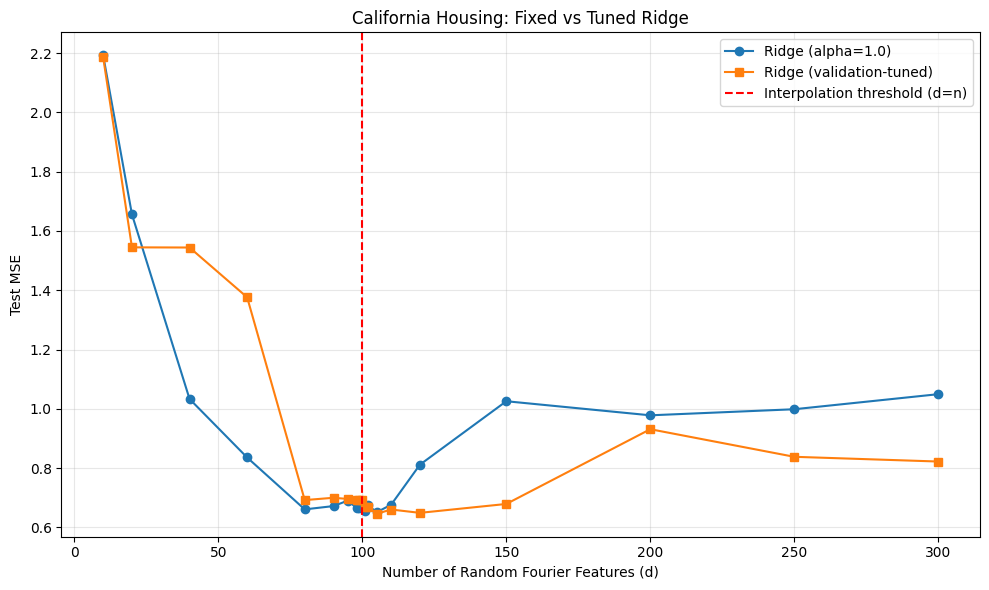

In [30]:

# Compare fixed and validation-tuned Ridge without Least Squares
plt.figure(figsize=(10, 6))

plt.plot(
    real_dimensions,
    real_ridge_test_errors,
    marker="o",
    label="Ridge (alpha=1.0)"
)

plt.plot(
    real_dimensions,
    tuned_ridge_test_errors,
    marker="s",
    label="Ridge (validation-tuned)"
)

plt.axvline(
    x=100,
    color="red",
    linestyle="--",
    label="Interpolation threshold (d=n)"
)

plt.xlabel("Number of Random Fourier Features (d)")
plt.ylabel("Test MSE")
plt.title("California Housing: Fixed vs Tuned Ridge")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("../results/GRAPH_NAME.png", dpi=300, bbox_inches="tight")
plt.show()
